# Step 3: Network design (version 0)

*Secure the Grid, step 3 · Parts 1, 2, 4 and 5 are written in `WRITEUP.md`; this notebook produces the design they describe.*

**Network.** A real utility's network topology is restricted critical-infrastructure information, so this design uses the Texas A&M **ACTIVSg70k** synthetic grid. It was built to match the statistics of real U.S. grids, sits on real towns, and is free to use. The notebook keeps every Chattanooga substation plus its direct neighbors: 49 substations and 65 links. Source: MATPOWER's copy of the case (Birchfield et al., IEEE Trans. Power Systems, 2017).

**Assumptions** (all printed in the summary below):
- Fiber is assumed to follow the power lines. Line length is estimated from each line's reactance at typical ohms per km for its voltage.
- Fiber loss is 0.35 dB/km, the rate measured on EPB's fiber (Evans et al., IEEE Access 2021). A link can carry QKD if its loss is at most 10 dB.
- QKD chains have at most 3 hops, the length EPB tested.
- The model does not mark control centers, so the highest-voltage, most central Chattanooga substation stands in for the main one, and the most central substation within 3 hops stands in for the backup.

**Version 0 rule.**
- Every link gets hybrid post-quantum cryptography.
- A budget of 8 QKD links goes first to the link between control centers, then to the highest-value substations: control centers, then 161 kV and above, then large loads.
- Each substation is checked for at least two separate paths to a control center.

Version 1 replaces this rule with the full value × exposure × feasibility formula.

In [1]:
import importlib.util, subprocess, sys, json, os
if importlib.util.find_spec("networkx") is None:
    %pip install -q networkx
from IPython.display import Image, display

D = "network_design"
print("This notebook is running in:", os.getcwd())
needed = ["parse_mp.py", "extract_chattanooga.py", "v0_design.py"]
missing = [f for f in needed if not os.path.exists(os.path.join(D, f))]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {os.path.abspath(D)}. Put the network_design/ folder from the ZIP "
        "in the same folder as this notebook (1-utc-secure-the-grid/), then run this cell again.")
if not os.path.exists(f"{D}/chatt_raw.json"):
    # Rebuild the extracted network from the raw MATPOWER file (19 MB, downloaded once)
    import urllib.request
    url = "https://raw.githubusercontent.com/MATPOWER/matpower/master/data/case_ACTIVSg70k.m"
    urllib.request.urlretrieve(url, f"{D}/case_ACTIVSg70k.m")
    subprocess.run([sys.executable, f"{D}/extract_chattanooga.py", f"{D}/case_ACTIVSg70k.m", f"{D}/chatt_raw.json"], check=True)
print("Network file ready:", f"{D}/chatt_raw.json")

This notebook is running in: /home/jovyan/tn_quant_final
Network file ready: network_design/chatt_raw.json


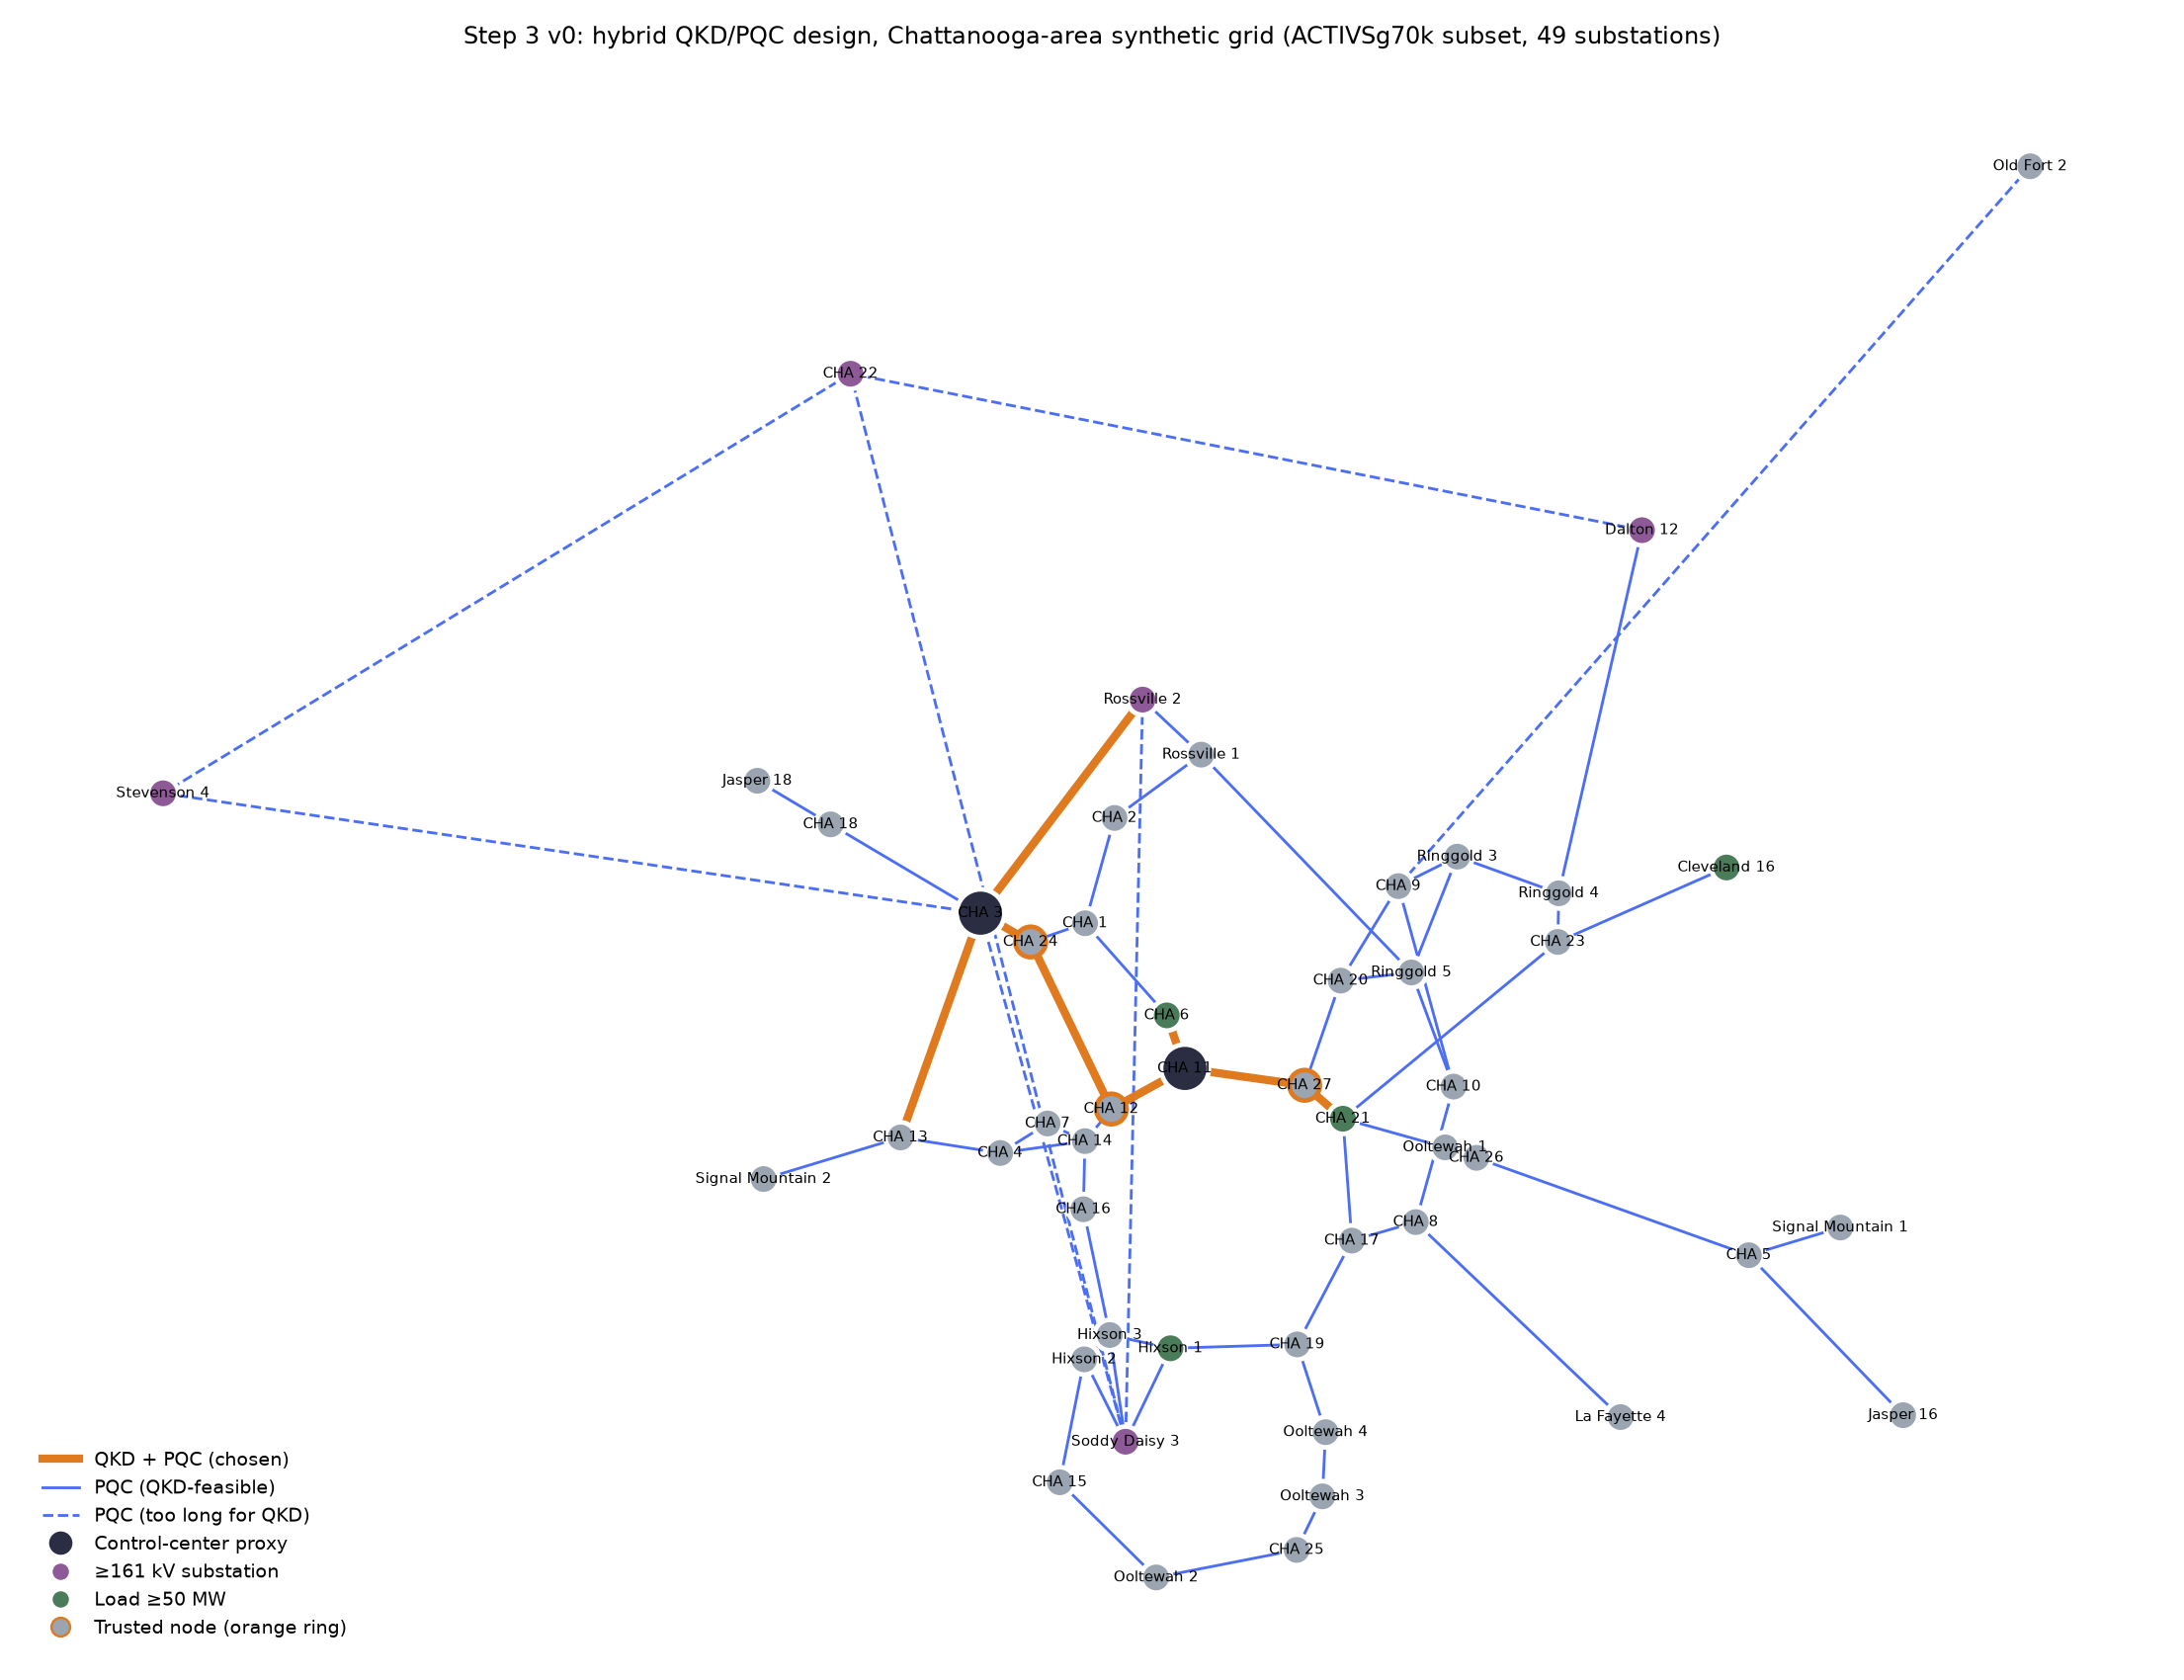

In [2]:
# Run the version 0 design. Writes v0_network_diagram.png to this folder and the numbers to network_design/v0_summary.json
r = subprocess.run([sys.executable, f"{D}/v0_design.py", f"{D}/chatt_raw.json", D, "v0_network_diagram.png"],
                   capture_output=True, text=True, check=True)
display(Image("v0_network_diagram.png"))

In [3]:
s = json.load(open(f"{D}/v0_summary.json"))
print(f"Substations: {s['substations']}   links: {s['links']}")
print(f"Link length (km): min {s['link_km']['min']}, median {s['link_km']['median']}, max {s['link_km']['max']}")
print(f"Links short enough for QKD: {s['qkd_feasible_links']} of {s['links']}")
print("Control-center proxies:", ", ".join(s["control_centers"]))
print(f"\nQKD links chosen ({len(s['qkd_links'])}):")
for a, b in s["qkd_links"]: print("  ", a, "-", b)
print("\nSubstations protected by QKD on every hop:")
for sub, path in s["qkd_protected"].items(): print(f"   {sub}: {len(path)-1} hop(s) via {' > '.join(path)}")
print("\nTrusted nodes (keys pass through unencrypted):", ", ".join(s["trusted_nodes"]))
print(f"\nSubstations with fewer than 2 separate paths to a control center ({len(s['substations_with_lt2_disjoint_paths'])}):")
print("  ", ", ".join(s["substations_with_lt2_disjoint_paths"]))
print("\nAssumptions:", json.dumps(s["assumptions"], indent=1))

Substations: 49   links: 65
Link length (km): min 2.1, median 6.8, max 83.1
Links short enough for QKD: 58 of 65
Control-center proxies: CHATTANOOGA 3, CHATTANOOGA 11

QKD links chosen (8):
   CHATTANOOGA 11 - CHATTANOOGA 12
   CHATTANOOGA 11 - CHATTANOOGA 27
   CHATTANOOGA 11 - CHATTANOOGA 6
   CHATTANOOGA 12 - CHATTANOOGA 24
   CHATTANOOGA 13 - CHATTANOOGA 3
   CHATTANOOGA 21 - CHATTANOOGA 27
   CHATTANOOGA 24 - CHATTANOOGA 3
   CHATTANOOGA 3 - ROSSVILLE 2

Substations protected by QKD on every hop:
   CHATTANOOGA 11: 3 hop(s) via CHATTANOOGA 3 > CHATTANOOGA 24 > CHATTANOOGA 12 > CHATTANOOGA 11
   ROSSVILLE 2: 1 hop(s) via CHATTANOOGA 3 > ROSSVILLE 2
   CHATTANOOGA 21: 2 hop(s) via CHATTANOOGA 11 > CHATTANOOGA 27 > CHATTANOOGA 21
   CHATTANOOGA 6: 1 hop(s) via CHATTANOOGA 11 > CHATTANOOGA 6
   CHATTANOOGA 12: 2 hop(s) via CHATTANOOGA 3 > CHATTANOOGA 24 > CHATTANOOGA 12
   CHATTANOOGA 13: 1 hop(s) via CHATTANOOGA 3 > CHATTANOOGA 13
   CHATTANOOGA 24: 1 hop(s) via CHATTANOOGA 3 > CHATT

## What to have ready (Step 3, Parts 1 and 2)

- `v0_network_diagram.png`: the first version. The final design is in `3g_final_design.ipynb`.
- From the summary: how many links are short enough for QKD, which links got QKD, how many trusted nodes the design creates, and which substations have only one path to a control center.
- In `WRITEUP.md`: the assumptions above, with sources, and what each result means for the utility.